In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from scipy.stats import multivariate_normal as mvn
from sklearn.model_selection import StratifiedKFold, KFold
from tensorflow.keras.callbacks import EarlyStopping



print("Installations Working!")

Installations Working!


## Distribution Setup


In [2]:
# Parameter Definitions

# Priors
p1, p2, p3, p4 = .25, .25, .25, .25


# Set Random Seed
rng = np.random.default_rng(1)

mu1 = [2, 1.5, 1]
mu2 = [1, -1, -1.5]
mu3 = [-2, 2, -2]
mu4 = [-2, -1, 2]


# Quick verification of mean equidistance


cov1 = [[2,   -1.5, .5],
              [-1.5, 4, 1],
              [.5, 1, 10]]

cov2 = [[2,   -.2, -.5],
              [-.2, 4, .5],
              [-.5, .5, 3]]

cov3 = [[2, .1, .5],
              [.1, 3, 1],
              [.5, 1, 3]]

cov4 = [[4, .1, .5],
              [.1, 4, .1],
              [.5, .1, 1]]



# Class overlap with Bhattacharyya Bound

def Bhattacharyya(mu1, mu2, cov1, cov2):
    mu1 = np.asarray(mu1).reshape(-1, 1)
    mu2 = np.asarray(mu2).reshape(-1, 1)
    
    diff = mu2 - mu1
    s_cov = (np.asarray(cov2) + np.asarray(cov1)) / 2

    B = .125 * diff.T @ np.linalg.inv(s_cov) @ diff + .5 * np.log(np.linalg.det(s_cov) / np.sqrt(np.linalg.det(cov1) * np.linalg.det(cov2)))

    return B

parameters = [[mu1, cov1], [mu2, cov2], [mu3, cov3], [mu4, cov4]]

iter = 1
B_pairs = []
err = 0
for mu1, cov1 in parameters:

    parameters_2 = parameters.copy()[iter :]
    
    for mu2, cov2 in parameters_2:
        B = Bhattacharyya(mu1, mu2, cov1, cov2)
        err += .25 * np.exp(-B)

    iter += 1        
    

print(f"Expected Error from BB: {err}")


Expected Error from BB: [[0.47263816]]


In [3]:
def g(mu, C, X_dist):
    return multivariate_normal(mu, C).pdf(X_dist)

def make_dist(N, seed=2):
    rng = np.random.default_rng(seed)
    priors = [.25, .25, .25, .25]

    labels = rng.choice(4, size=N, p=priors)
    X = np.zeros((N, 3))

    for c in range(4):
        mu, C = parameters[c]
        idx = (labels == c)
        X[idx] = rng.multivariate_normal(mu, C, size=idx.sum())

    return labels, X

In [4]:
Y_100, X_100 = make_dist(100)
Y_500, X_500 = make_dist(500)
Y_1000, X_1000 = make_dist(1000)
Y_5000, X_5000 = make_dist(5000)
Y_10000, X_10000 = make_dist(10000)
Y_100000, X_100000 = make_dist(100000)



In [5]:
import numpy as np
from scipy.stats import multivariate_normal as mvn

priors = [0.25, 0.25, 0.25, 0.25]

# Log of P(c) * p(x | c) for each class, one column per class
log_scores = np.column_stack([
    np.log(priors[c]) + mvn(mu, C).logpdf(X_100000)
    for c, (mu, C) in enumerate(parameters)
])

# MAP decision: class with the largest score for each sample
map_decisions = log_scores.argmax(axis=1)

# Fraction of test samples MAP gets wrong
map_error = np.mean(map_decisions != Y_100000)
print(f"MAP (minimum) error: {map_error:.4f}")

MAP (minimum) error: 0.1786


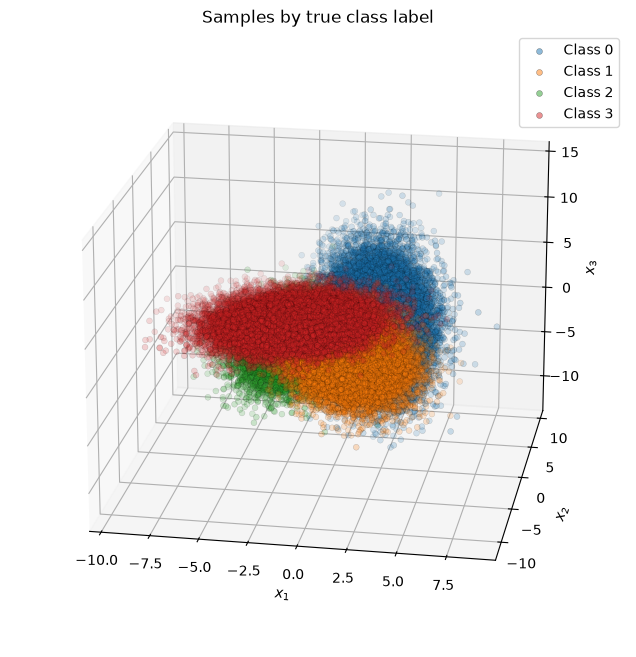

In [6]:
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection='3d')
markers = {0: 'o', 1: 'o', 2: 'o', 3: 'o'}                         # circle, triangle, square
colors  = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green', 3: 'tab:red'}

for k in [0, 1, 2, 3]:
    pts = X_100000[Y_100000 == k]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2],
               marker=markers[k], color=colors[k],
               s=18, alpha=0.5, edgecolors='k', linewidths=0.3,
               label=f"Class {k}")
ax.view_init(elev=20, azim=280)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.set_title("Samples by true class label")
ax.legend()
plt.show()

## Bayes Classifier

In [7]:
# Theoretically Optimal Classifier (true pdf, MAP rule)

log_scores = np.column_stack([np.log(0.25) + mvn(mu, C).logpdf(X_100000) for mu, C in parameters])
map_error = np.mean(log_scores.argmax(axis=1) != Y_100000)
print(f"Theoretically optimal (MAP) test error: {map_error:.4f}")
print("======================================================================================")


Theoretically optimal (MAP) test error: 0.1786


## Multi Layer Perceptrons


In [8]:

def model_build(P):
    model = Sequential([
        Input(shape=(3,)),
        Dense(P, activation='elu'),        # one hidden layer, smooth-ramp activation
        Dense(4, activation='softmax')     # output layer: class posteriors
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',   # = average negative log-likelihood
        metrics=['accuracy']
    )
    return model


def fit_model(model, x, y, target_steps=2000, batch=64, max_epochs=500):
    # Give every fit about the same number of gradient steps, whatever the data size
    steps_per_epoch = int(np.ceil(len(x) / batch))
    epochs = min(max_epochs, int(np.ceil(target_steps / steps_per_epoch)))
    stop = EarlyStopping(monitor='loss', patience=10, min_delta=1e-4)
    model.fit(x, y, epochs=epochs, batch_size=batch, callbacks=[stop], verbose=0)
    return model


# Final Training with Random Restarts

def train_final(x, y, P, n_restarts=5):
    # Keep the restart with the highest training log-likelihood (lowest training loss)
    best_loss, best_weights = np.inf, None
    for r in range(n_restarts):
        tf.keras.backend.clear_session()
        m = fit_model(model_build(P), x, y)          # new random initialization each time
        train_loss = m.evaluate(x, y, verbose=0)[0]
        print(f"   restart {r + 1}: training loss = {train_loss:.4f}", flush=True)
        if train_loss < best_loss:
            best_loss, best_weights = train_loss, m.get_weights()

    final = model_build(P)
    final.set_weights(best_weights)
    return final, best_loss


# Model Order Selection + Final Training

def train_and_test_model(x_train, y_train):

    p_width = [1, 2, 4, 8, 16, 32, 64]
    num_folds = 10
    kfold = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=0)

    cv_errors = {}

    for p in p_width:
        err_per_fold = []

        for train, val in kfold.split(x_train, y_train):
            tf.keras.backend.clear_session()
            model = fit_model(model_build(p), x_train[train], y_train[train])

            scores = model.evaluate(x_train[val], y_train[val], verbose=0)
            err_per_fold.append(1 - scores[1])

        cv_errors[p] = np.mean(err_per_fold)
        print(f"10-fold CV error for X_{len(x_train)} at P = {p}: {cv_errors[p]:.4f}", flush=True)

    # Smallest CV error wins; ties go to the smaller P
    opt_p = min(cv_errors, key=cv_errors.get)

    # Retrain with the chosen P on ALL training data, with random restarts
    print(f"Training final model for X_{len(x_train)} with P = {opt_p}", flush=True)
    final_model, train_loss = train_final(x_train, y_train, opt_p)

    return cv_errors, opt_p, final_model

In [9]:

d_sets = [[X_100, Y_100], [X_500, Y_500], [X_1000, Y_1000], [X_5000, Y_5000], [X_10000, Y_10000]]

results = []
all_cv_errors = {}

for x_train, y_train in d_sets:
    cv_errors, p, model = train_and_test_model(x_train, y_train)
    test_err = 1 - model.evaluate(X_100000, Y_100000, verbose=0)[1]

    N = len(y_train)
    results.append((N, p, cv_errors[p], test_err))
    all_cv_errors[N] = cv_errors

    print(f"X_{N} | Optimal Neurons: {p} | CV Error: {cv_errors[p]:.4f} | Test Error: {test_err:.4f}")
    print("======================================================================================")



10-fold CV error for X_100 at P = 1: 0.5900
10-fold CV error for X_100 at P = 2: 0.3800
10-fold CV error for X_100 at P = 4: 0.2700
10-fold CV error for X_100 at P = 8: 0.2300
10-fold CV error for X_100 at P = 16: 0.2200
10-fold CV error for X_100 at P = 32: 0.2200
10-fold CV error for X_100 at P = 64: 0.2200
Training final model for X_100 with P = 32
   restart 1: training loss = 0.4259
   restart 2: training loss = 0.4193
   restart 3: training loss = 0.4330
   restart 4: training loss = 0.4270
   restart 5: training loss = 0.4240
X_100 | Optimal Neurons: 32 | CV Error: 0.2200 | Test Error: 0.2086
10-fold CV error for X_500 at P = 1: 0.5160
10-fold CV error for X_500 at P = 2: 0.3740
10-fold CV error for X_500 at P = 4: 0.2640
10-fold CV error for X_500 at P = 8: 0.2500
10-fold CV error for X_500 at P = 16: 0.2600
10-fold CV error for X_500 at P = 32: 0.2620
10-fold CV error for X_500 at P = 64: 0.2540
Training final model for X_500 with P = 8
   restart 1: training loss = 0.5324
  

In [10]:

print(f"{'N':>7} | {'P':>3} | {'CV error':>8} | {'Test error':>10}")
for N, p, cv_err, test_err in results:
    print(f"{N:>7} | {p:>3} | {cv_err:>8.4f} | {test_err:>10.4f}")
print(f"Theoretically optimal test error: {map_error:.4f}")


      N |   P | CV error | Test error
    100 |  32 |   0.2200 |     0.2086
    500 |   8 |   0.2500 |     0.1885
   1000 |  32 |   0.1760 |     0.1834
   5000 |  16 |   0.1876 |     0.1825
  10000 |  64 |   0.1772 |     0.1804
Theoretically optimal test error: 0.1786


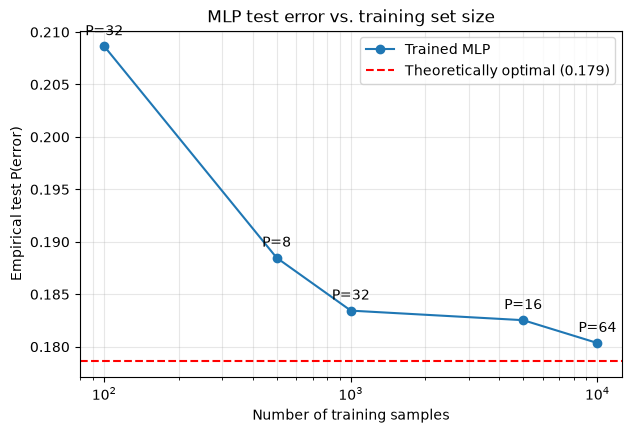

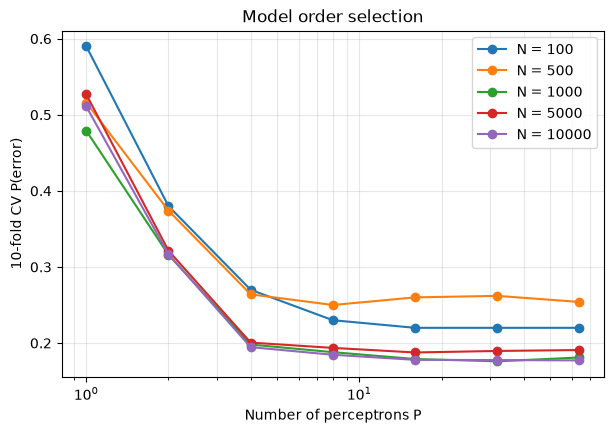

In [11]:

Ns, Ps, cv_errs, test_errs = zip(*results)

plt.figure(figsize=(7, 4.5))
plt.semilogx(Ns, test_errs, 'o-', label='Trained MLP')
plt.axhline(map_error, color='r', linestyle='--', label=f'Theoretically optimal ({map_error:.3f})')
for N, p, e in zip(Ns, Ps, test_errs):
    plt.annotate(f'P={p}', (N, e), textcoords='offset points', xytext=(0, 8), ha='center')
plt.xlabel('Number of training samples')
plt.ylabel('Empirical test P(error)')
plt.title('MLP test error vs. training set size')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()


# Plot 2: CV error vs number of perceptrons, one curve per training set

plt.figure(figsize=(7, 4.5))
for N, cv in all_cv_errors.items():
    plt.semilogx(list(cv.keys()), list(cv.values()), 'o-', label=f'N = {N}')
plt.xlabel('Number of perceptrons P')
plt.ylabel('10-fold CV P(error)')
plt.title('Model order selection')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()